# Homework 5 — Convolutional Neural Networks (PyTorch)
**CSCI1409 Deep Learning | Aidyn Abirov | Week 5**

Fill in every `# TODO`. Do **not** change the `assert` lines: they tell you when a cell is correct. Write your explanations in the **Your answer** cells.

- **Warm-up, Task 1, Task 2: no AI.** Task 3: AI allowed for explanations and debugging only (record which tool and what for).
- Save as `Surname_Firstname_Homework05.ipynb`, restart the kernel, **Run All**, and submit via Teams.

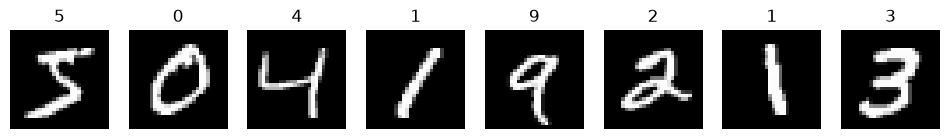

In [72]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

torch.manual_seed(0)

# MNIST: 28x28 grayscale handwritten digits (downloads about 12 MB the first time)
to_tensor = torchvision.transforms.ToTensor()
train_set = torchvision.datasets.MNIST("data", train=True, download=True, transform=to_tensor)
test_set = torchvision.datasets.MNIST("data", train=False, download=True, transform=to_tensor)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1000)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, range(8)):
    img, label = train_set[i]
    ax.imshow(img[0], cmap="gray"); ax.set_title(label); ax.axis("off")
plt.show()

## Warm-up — PyTorch in 10 minutes (no AI)
This is your first PyTorch homework. Run each cell, read the comments, and fill in the small TODOs.

**1. Tensors and shapes.** A tensor is PyTorch's version of a NumPy array. A batch of images always has shape **(batch, channels, height, width)**.

In [73]:
x = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
print(x.shape)            # torch.Size([2, 3])
print(x[0], x[:, 1])      # first row, second column

images, labels = next(iter(train_loader))
print(images.shape)       # (64, 1, 28, 28): 64 images, 1 channel (grayscale), 28x28 pixels
print(labels.shape)       # (64,): one label per image

# TODO: create a batch of 4 grayscale 28x28 images filled with zeros
fake_batch = torch.zeros(4, 1, 28, 28)

assert fake_batch.shape == (4, 1, 28, 28)

torch.Size([2, 3])
tensor([1., 2., 3.]) tensor([2., 5.])
torch.Size([64, 1, 28, 28])
torch.Size([64])


**2. Automatic gradients.** In Homework 4 you used $L(w) = (w^2-1)^2$ with gradient $g(w) = 4w^3 - 4w$. PyTorch can compute that gradient for you.

In [74]:
w = torch.tensor(2.0, requires_grad=True)   # "track gradients for w"
L = (w**2 - 1)**2
L.backward()                                # compute dL/dw
print(w.grad)                               # 4*8 - 4*2 = 24

# TODO: repeat for w = 1.5 and store the gradient in grad_15
w = torch.tensor(1.5, requires_grad=True)
L = (w**2 - 1)**2
L.backward()
grad_15 = w.grad
assert torch.isclose(grad_15, torch.tensor(7.5))   # the same value as in Homework 4

tensor(24.)


**3. One gradient-descent step with an optimizer.** `torch.optim.SGD` does exactly the update $w \leftarrow w - \eta\, g$ from Homework 4.

In [75]:
w = torch.tensor(1.5, requires_grad=True)
optimizer = torch.optim.SGD([w], lr=0.1)

L = (w**2 - 1)**2
optimizer.zero_grad()   # 1. clear any old gradient
L.backward()            # 2. compute the new gradient (7.5)
optimizer.step()        # 3. w <- w - lr * gradient
print(w.item())         # 1.5 - 0.1 * 7.5 = 0.75, the same as your Homework 4 hand update

0.75


**Question W.** In your own words, what does each of `zero_grad()`, `backward()`, and `step()` do?

zero_grad - clear the history of autograd
backward() makes backpropogation and calculate the gradients
step() is update parameters

**Your answer:**

## Task 1 — Convolution by hand and from scratch (no AI, about 30 minutes)

**1a. By hand.** Slide the 3×3 kernel over the 5×5 image (no padding, stride 1). At each position, multiply the overlapping numbers and add them up. Write the 3×3 result on paper, then type it into `hand_result`.

```
image                 kernel
0 0 0 0 0             -1  0  1
0 1 1 1 0             -1  0  1
0 1 1 1 0             -1  0  1
0 1 1 1 0
0 0 0 0 0
```

In [76]:
image = torch.tensor([[0, 0, 0, 0, 0],
                      [0, 1, 1, 1, 0],
                      [0, 1, 1, 1, 0],
                      [0, 1, 1, 1, 0],
                      [0, 0, 0, 0, 0]], dtype=torch.float32)
kernel = torch.tensor([[-1, 0, 1],
                       [-1, 0, 1],
                       [-1, 0, 1]], dtype=torch.float32)

# TODO: type the 3x3 result you computed by hand
hand_result = torch.tensor([[2., 0., -2.],
                            [3., 0., -3.],
                            [2., 0., -2.]])

In [77]:
H, W = image.shape
k = kernel.shape

print(f"H shape. {H}")
print(f"W shape. {W}")
print(f"k shape. {k}")

H shape. 5
W shape. 5
k shape. torch.Size([3, 3])


**1b. From scratch.** Complete `conv2d_scratch` with two loops (do not call `F.conv2d` inside it). Then compare it with your hand result and with PyTorch's `F.conv2d`.

Note: PyTorch's "convolution" does **not** flip the kernel (mathematicians call this cross-correlation). Your function should not flip it either.

In [78]:
def conv2d_scratch(image, kernel):
    H, W = image.shape
    k = kernel.shape[0]
    out = torch.zeros(H - k + 1, W - k + 1)
    for i in range(H - k + 1):
        for j in range(W - k + 1):
            point = image[i:i+k, j:j+k]


            out[i, j] = (point * kernel).sum()   # replace this line
    return out

mine = conv2d_scratch(image, kernel)
torch_out = F.conv2d(image[None, None], kernel[None, None])[0, 0]   # PyTorch wants (batch, channels, H, W)
print(mine); print(torch_out)
assert torch.allclose(mine, hand_result), "your function differs from your hand calculation"
assert torch.allclose(mine, torch_out), "your function differs from F.conv2d"

tensor([[ 2.,  0., -2.],
        [ 3.,  0., -3.],
        [ 2.,  0., -2.]])
tensor([[ 2.,  0., -2.],
        [ 3.,  0., -3.],
        [ 2.,  0., -2.]])


**1c. Output size.** For input size $n$, kernel size $k$, padding $p$, and stride $s$:
$$\text{output size} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1$$
First fill in the last column of this table by hand. Then complete the function and run the check.

| $n$ | $k$ | $p$ | $s$ | output size |
|---|---|---|---|---|
| 5 | 3 | 0 | 1 | 3 |
| 5 | 3 | 1 | 1 | 5 |
| 5 | 3 | 0 | 2 | 2 |
| 28 | 3 | 1 | 1 | 28 |
| 28 | 5 | 0 | 1 | 24 |
| 28 | 3 | 1 | 2 | 14 |

In [79]:
def conv_output_size(n, k, p, s):
    return (n + 2 * p - k)//s + 1

for n, k, p, s in [(5, 3, 0, 1), (5, 3, 1, 1), (5, 3, 0, 2), (28, 3, 1, 1), (28, 5, 0, 1), (28, 3, 1, 2)]:
    real = F.conv2d(torch.zeros(1, 1, n, n), torch.zeros(1, 1, k, k), padding=p, stride=s).shape[-1]
    print(f"n={n:2d} k={k} p={p} s={s}: formula {conv_output_size(n, k, p, s)}, PyTorch {real}")
    assert conv_output_size(n, k, p, s) == real

n= 5 k=3 p=0 s=1: formula 3, PyTorch 3
n= 5 k=3 p=1 s=1: formula 5, PyTorch 5
n= 5 k=3 p=0 s=2: formula 2, PyTorch 2
n=28 k=3 p=1 s=1: formula 28, PyTorch 28
n=28 k=5 p=0 s=1: formula 24, PyTorch 24
n=28 k=3 p=1 s=2: formula 14, PyTorch 14


**1d. Kernels on a real digit.** Create a horizontal-edge kernel (hint: the transpose of the vertical one) and a 3×3 blur kernel (every entry $1/9$). The code then applies all three kernels to a test digit with `padding=1` and shows the feature maps.

In [80]:
ker = torch.tensor([
    [-1,0,1],
    [-1,0,1],
    [-1,0,1]
])

print(ker)
print(ker.T)
print(ker.T.T)


tensor([[-1,  0,  1],
        [-1,  0,  1],
        [-1,  0,  1]])
tensor([[-1, -1, -1],
        [ 0,  0,  0],
        [ 1,  1,  1]])
tensor([[-1,  0,  1],
        [-1,  0,  1],
        [-1,  0,  1]])


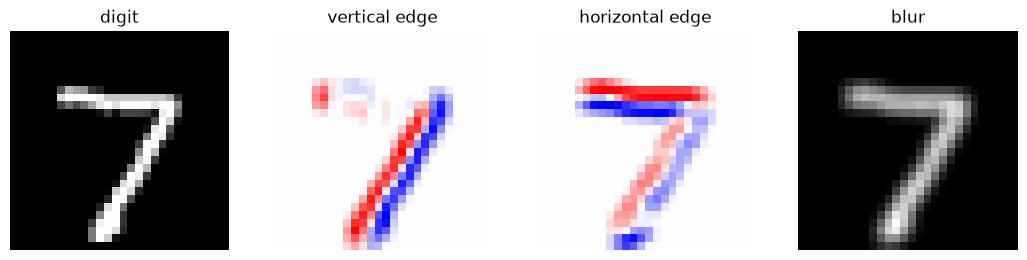

In [81]:
digit = test_set[0][0]          # shape (1, 28, 28)

vertical = kernel
horizontal = kernel.T         # TODO
blur = torch.ones_like(vertical)/9                   # TODO

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
axes[0].imshow(digit[0], cmap="gray"); axes[0].set_title("digit")
for ax, (name, kern) in zip(axes[1:], [("vertical edge", vertical), ("horizontal edge", horizontal), ("blur", blur)]):
    fmap = F.conv2d(digit[None], kern[None, None], padding=1)[0, 0]
    assert fmap.shape == (28, 28)
    ax.imshow(fmap, cmap="bwr", vmin=-3, vmax=3) if "edge" in name else ax.imshow(fmap, cmap="gray"); ax.set_title(name)
for ax in axes: ax.axis("off")
plt.show()

**Questions 1.**
1. In your hand result, which positions are positive, which are negative, and which are zero? Explain using the left and right edges of the bright square.
2. Which strokes of the digit does each edge kernel light up? What does the blur kernel do?
3. Why is the result in 1a 3×3 and not 5×5? What does `padding=1` change?

**Your answer:**

1 in the left part we can see positive numbers so it says that there was transition from dark to bright tone
in the middle is 0 and right part is negative, that says there were transition from bright color to dark
2 vertical filter highlight left and right boundaries and vertical strokes
horizontal filter highlight upper and lower boundaries and horizontal strokes
blur makes average each neibors in the window
3 because kernle should fit into image, so if we put into formula we take 5 - 3 + 1 = 3 is one side of our feature map
padding add some 0value borders


## Task 2 — Pooling, shapes, and parameter counts (no AI, about 20 minutes)

**2a. Max pooling by hand.** Split the 4×4 grid into 2×2 blocks (stride 2) and keep the largest number in each block. Type your 2×2 result into `hand_pool`, then complete `maxpool_scratch` (do not call `F.max_pool2d` inside it).

```
1 3 2 0
4 6 1 1
0 2 5 7
1 0 3 2
```

In [82]:
grid = torch.tensor([[1, 3, 2, 0],
                     [4, 6, 1, 1],
                     [0, 2, 5, 7],
                     [1, 0, 3, 2]], dtype=torch.float32)

# TODO: type your 2x2 hand result
hand_pool = torch.tensor([[6., 2.],
                          [2., 7.]])

def maxpool_scratch(x, size=2):
    H, W = x.shape
    out = torch.zeros(H // size, W // size)
    for i in range(H // size):
        for j in range(W // size):
            # TODO: take the size x size block for output position (i, j) and keep its maximum
            maxx = torch.max(x[i*size:(i+1)*size, j*size:(j+1)*size])
            out[i, j] = maxx   # replace this line
    return out

mine = maxpool_scratch(grid)
torch_out = F.max_pool2d(grid[None, None], 2)[0, 0]
print(mine); print(torch_out)
assert torch.allclose(mine, hand_pool) and torch.allclose(mine, torch_out)

tensor([[6., 2.],
        [2., 7.]])
tensor([[6., 2.],
        [2., 7.]])


**2b. Trace the shapes.** Here is the CNN you will train in Task 3. For **one** input image of shape (1, 1, 28, 28), fill in this table **by hand** first: the output shape after each layer and the number of trainable parameters in that layer.

Parameters of `Conv2d(c_in, c_out, k)`: $c_{out} \times c_{in} \times k \times k$ weights $+\ c_{out}$ biases. Parameters of `Linear(n_in, n_out)`: $n_{in} \times n_{out} + n_{out}$.

| layer | output shape | parameters |
|---|---|---|
| Conv2d(1, 8, 3, padding=1)|1,8, 28, 28 | 80|
| ReLU |1,8,28,28 | 0|
| MaxPool2d(2) |1, 8, 14,14 |0|
| Conv2d(8, 16, 3, padding=1)|1, 16, 14,14 |1168|
| ReLU | 1, 16, 14, 14|0|
| MaxPool2d(2) | 1, 16, 7, 7| 0|
| Flatten | 1, 784| 0 |
| Linear(784, 10) |10,|7850 |

In [83]:
cnn = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(8, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(16 * 7 * 7, 10),
)

# TODO: copy your table into these two lists (8 entries each, in order)
my_shapes = [(1, 8, 28, 28), 
             (1,8,28,28),
             (1,8,14,14),
             (1,16,14,14),   # first one done for you
             (1,16,14,14),   # first one done for you
             (1,16,7,7),
             (1,784),(1,10)]   # first one done for you
my_params = [80, 0, 0,1168, 0,0,0,7850]

x = torch.zeros(1, 1, 28, 28)
for layer, expected_shape, expected_params in zip(cnn, my_shapes, my_params):
    x = layer(x)
    n_params = sum(p.numel() for p in layer.parameters())
    print(f"{layer.__class__.__name__:10s} {str(tuple(x.shape)):18s} params = {n_params}")
    assert tuple(x.shape) == expected_shape, f"shape after {layer} is wrong in your table"
    assert n_params == expected_params, f"parameter count of {layer} is wrong in your table"
assert len(my_shapes) == len(my_params) == 8, "fill in all 8 rows"
print("total parameters:", sum(my_params))

Conv2d     (1, 8, 28, 28)     params = 80
ReLU       (1, 8, 28, 28)     params = 0
MaxPool2d  (1, 8, 14, 14)     params = 0
Conv2d     (1, 16, 14, 14)    params = 1168
ReLU       (1, 16, 14, 14)    params = 0
MaxPool2d  (1, 16, 7, 7)      params = 0
Flatten    (1, 784)           params = 0
Linear     (1, 10)            params = 7850
total parameters: 9098


**2c. CNN vs MLP.** This MLP also classifies 28×28 digits. Compute its parameter count **by hand**, type it in, and compare with the CNN.

In [84]:
mlp = nn.Sequential( #(1,1,28,28) 0
    nn.Flatten(),#(1, 784) 0
    nn.Linear(784, 128), # (1, 128) 100352
    nn.ReLU(), # (1,128) 0
    nn.Linear(128, 10), # (1, 10) 1280
)

mlp_params_by_hand = sum([0,100480,0,1290])   # TODO
mlp_params = sum(p.numel() for p in mlp.parameters())
print(mlp_params)
assert mlp_params_by_hand == mlp_params
print(f"MLP: {mlp_params} parameters, CNN: {sum(my_params)} parameters, ratio {mlp_params / sum(my_params):.1f}x")

101770
MLP: 101770 parameters, CNN: 9098 parameters, ratio 11.2x


**Questions 2.**
1. What does max pooling keep, and what does it throw away? Why does it make the next layer cheaper?
2. The first conv layer looks at all 784 pixels but has only 80 parameters. How is that possible? (Hint: think about how the same kernel is used at every position.)

**Your answer:**

1 maxpoll keeps the maximum value inside the window and throw others, and it makes windows size times smaller next layer input, so it make it efficient
2 we had parameters like that Conv2d(1, 8, 3, padding=1) so we have 1 channel 8 filter and kernel of size 3x3
so lets calculate our weights is 3*3 = 9. Also have a one bias per filter so 9 + 1 = 10 then we have total 8 filters is 10 * 8 = 80

## Task 3 — Train a CNN on MNIST (AI allowed, about 40 minutes)
AI may be used to explain concepts or help debug this task only. Record which tool you used and for what, and be ready to explain every line.

**3a. The model.** Write the same CNN as in Task 2, but as a class. Create the layers in `__init__` and connect them in `forward`.

In [85]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: create conv1 (1 -> 8 channels), conv2 (8 -> 16 channels), both 3x3 with padding=1,
        #       one MaxPool2d(2) layer called pool, and fc = Linear(16 * 7 * 7, 10)
        self.conv1 = nn.Conv2d(1, 8, 3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(8, 16, 3, padding=1)
        self.flatten = nn.Flatten()
        self.linear = nn.Linear(784, 10)

    def forward(self, x):
        # TODO: conv1 -> ReLU -> pool -> conv2 -> ReLU -> pool -> flatten -> fc
        #       use F.relu(...) for ReLU and x.flatten(1) to flatten everything except the batch dimension
        x = self.pool(
            self.relu(
            self.conv1(x)))

        x = self.pool(
                    self.relu(
                    self.conv2(x)))
        
        x = x.flatten(1)
        return self.linear(x)

model = SmallCNN()
assert model(torch.zeros(5, 1, 28, 28)).shape == (5, 10), "output should be (batch, 10)"
assert sum(p.numel() for p in model.parameters()) == sum(my_params), "parameter count should match Task 2"
print("SmallCNN OK")

SmallCNN OK


**3b. Accuracy and training.** Complete `accuracy` (one line) and the five TODO lines in `train`. Each update uses a **mini-batch** of 64 images instead of all 60,000 — this is called stochastic gradient descent (SGD), and it is the same update as Homework 4, just with a gradient estimated from a small batch.

In [86]:
def accuracy(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():                       # no gradients needed for evaluation
        for images, labels in loader:
            logits = model(images)              # shape (batch, 10)
            predictions = torch.argmax(logits, dim=1)                 # TODO: index of the largest logit in each row (hint: argmax)
            correct += (predictions == labels).sum().item()
    return correct / len(loader.dataset)

def train(model, epochs=2, lr=0.1):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        for images, labels in train_loader:
            logits = model(images)
            loss = F.cross_entropy(logits, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            # TODO 1: forward pass: logits = ...
            # TODO 2: loss = F.cross_entropy(...)
            # TODO 3: clear old gradients
            # TODO 4: backpropagate
            # TODO 5: gradient-descent step
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: test accuracy {accuracy(model, test_loader):.4f}")
    return losses

**3c. Train both models.** Training takes about a minute on a laptop CPU. The MLP from Task 2 is the baseline.

CNN
epoch 1: test accuracy 0.9737
epoch 2: test accuracy 0.9791
MLP
epoch 1: test accuracy 0.9250
epoch 2: test accuracy 0.9475
CNN: 0.9791 with 9098 parameters
MLP: 0.9475 with 101770 parameters


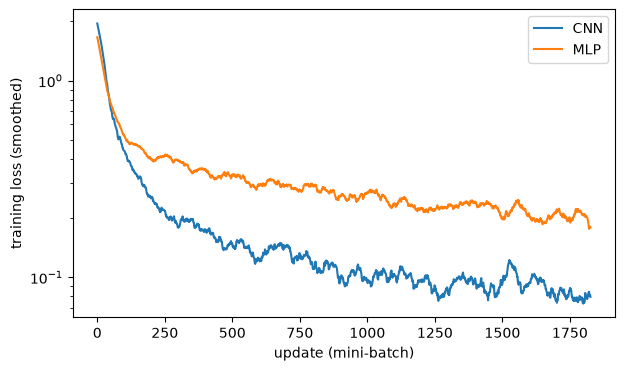

In [87]:
torch.manual_seed(0)
cnn_model = SmallCNN()
print("CNN"); cnn_losses = train(cnn_model)

torch.manual_seed(0)
mlp_model = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
print("MLP"); mlp_losses = train(mlp_model)

cnn_acc, mlp_acc = accuracy(cnn_model, test_loader), accuracy(mlp_model, test_loader)
print(f"CNN: {cnn_acc:.4f} with {sum(p.numel() for p in cnn_model.parameters())} parameters")
print(f"MLP: {mlp_acc:.4f} with {sum(p.numel() for p in mlp_model.parameters())} parameters")
assert cnn_acc > 0.97, "the CNN should reach above 97% test accuracy; check your training loop"

smooth = lambda v: np.convolve(v, np.ones(50) / 50, mode="valid")   # moving average over 50 batches
plt.figure(figsize=(7, 4))
plt.plot(smooth(cnn_losses), label="CNN"); plt.plot(smooth(mlp_losses), label="MLP")
plt.xlabel("update (mini-batch)"); plt.ylabel("training loss (smoothed)"); plt.yscale("log"); plt.legend(); plt.show()

**3d. Look inside the CNN.** The three plots below show (1) the 8 learned first-layer filters, (2) what those filters produce for one test digit, and (3) test digits the CNN got wrong. Just run the cells and study the pictures.

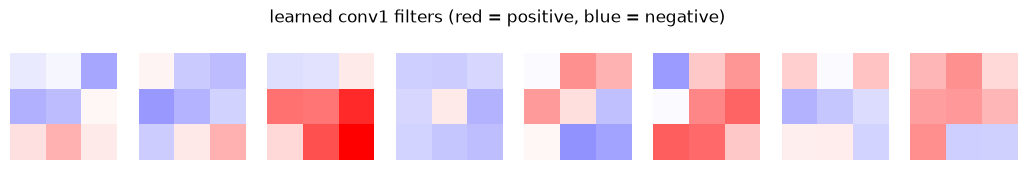

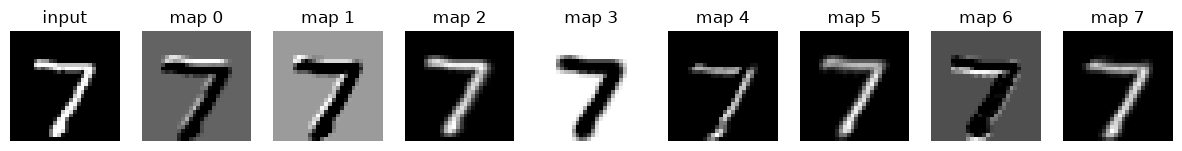

In [88]:
filters = cnn_model.conv1.weight.detach()          # shape (8, 1, 3, 3)
fig, axes = plt.subplots(1, 8, figsize=(13, 2))
for ax, f in zip(axes, filters):
    m = filters.abs().max()
    ax.imshow(f[0], cmap="bwr", vmin=-m, vmax=m); ax.axis("off")
fig.suptitle("learned conv1 filters (red = positive, blue = negative)"); plt.show()

with torch.no_grad():
    fmaps = F.relu(cnn_model.conv1(digit[None]))[0]   # shape (8, 28, 28)
fig, axes = plt.subplots(1, 9, figsize=(15, 2))
axes[0].imshow(digit[0], cmap="gray"); axes[0].set_title("input")
for k, ax in enumerate(axes[1:]):
    ax.imshow(fmaps[k], cmap="gray"); ax.set_title(f"map {k}")
for ax in axes: ax.axis("off")
plt.show()

209 of 10000 test digits misclassified


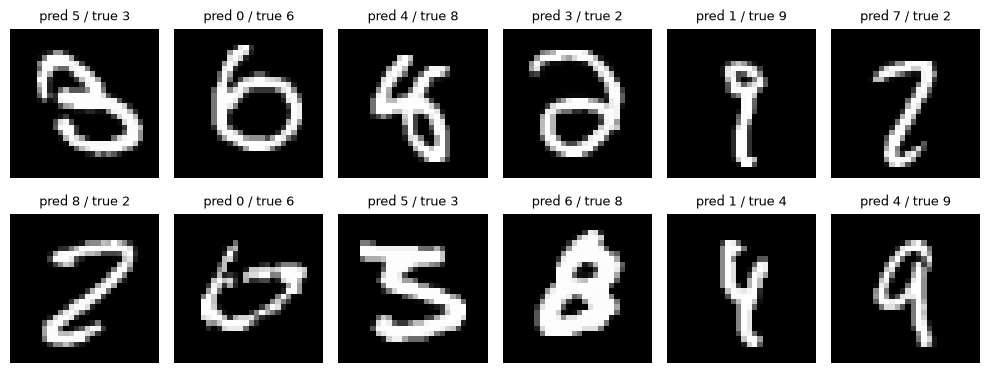

In [89]:
wrong_images, wrong_pred, wrong_true = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        preds = cnn_model(images).argmax(dim=1)
        mask = preds != labels
        wrong_images.append(images[mask]); wrong_pred.append(preds[mask]); wrong_true.append(labels[mask])
wrong_images, wrong_pred, wrong_true = torch.cat(wrong_images), torch.cat(wrong_pred), torch.cat(wrong_true)
print(f"{len(wrong_images)} of {len(test_set)} test digits misclassified")

fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for ax, img, p, t in zip(axes.ravel(), wrong_images, wrong_pred, wrong_true):
    ax.imshow(img[0], cmap="gray"); ax.set_title(f"pred {p.item()} / true {t.item()}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Questions 3.**
1. Compare the CNN and the MLP: test accuracy and number of parameters. Which uses its parameters better, and why?
2. Do any learned filters look like the edge kernels from Task 1? In the feature maps, which parts of the digit light up?
3. Look at the misclassified digits. Would you have got them right? What do the mistakes have in common?

**Your answer:**

The CNN got 0.9791 test accuracy and has 9,098 parameters. The MLP got 0.9475 test accuracy and has 101,770 parameters. The CNN uses its parameters better because it has fewer parameters, and the same filters are reused across the image.

Some learned filters look like edge filters. Their feature maps light up around the digit’s strokes and edges.

Many mistakes are digits that look similar or are written unclearly. I think I could recognize some of them, but a few are hard to tell apart.

**Optional (not required).** Shift every test image 3 pixels to the right with `torch.roll(images, shifts=3, dims=3)` and measure the accuracy of both models on the shifted images. Which model is more robust to the shift, and why?

In [90]:
# Optional: your code here

## Submission checklist
- [ ] Every `# TODO` filled, every `assert` passes, **Kernel → Restart & Run All** works
- [ ] All **Your answer** cells written (W, 1, 2, 3)
- [ ] Warm-up, Tasks 1–2 done without AI; references listed
- [ ] Task 3 AI use recorded (tool + what for), or "no AI used"

**References / AI use:**